# 06 - LSTM forecast of SPEI-3 (Mekong Delta)

Spatio-temporal LSTM trained on `gold_drought_features.parquet`.

**Task:** from the last **T = 12 months** of features at one grid cell (`latitude`, `longitude`), predict `spei_3m` **`HORIZON` month(s) ahead** (default 1).

**Pipeline:** load -> time-based split -> `MinMaxScaler` (fit on train only) -> sliding windows per cell -> LSTM -> loss curve -> test predictions + metrics -> save everything.

**Outputs** (paths relative to the project root):

| File | Content |
| --- | --- |
| `models/lstm_spei3m.pt` | model weights + config |
| `models/lstm_scaler.pkl` | fitted `MinMaxScaler` |
| `data/gold/drought_forecasting/lstm_predictions_2022_2025.csv` | test predictions |
| `reports/evaluation/lstm_metrics.json` | metrics |
| `reports/figures/lstm_loss_curve.png` | train vs validation loss |
| `reports/figures/lstm_actual_vs_pred.png` | actual vs predicted |

## 1. Setup and configuration

In [ ]:
import json
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

# ---- Configuration -------------------------------------------------------
T = 12                      # window length in months
HORIZON = 1                 # months ahead to predict (target = spei_3m at t + HORIZON)
TARGET = "spei_3m"
DROUGHT_THRESHOLD = -1.0    # SPEI below this = drought (moderately dry or worse)

# Time-based split on the TARGET month (inputs may reach back into earlier periods)
VAL_START = "2019-01-01"    # train: target before this
TEST_START = "2022-01-01"   # validation: VAL_START .. TEST_START; test: TEST_START .. end

NUMERIC_FEATURES = [
    "temp_mean_celsius", "precip_monthly_mm", "water_balance_mm",
    "soil_moisture_surface", "soil_moisture_rootzone",
    "spi_3m", "spei_3m",
    "precip_lag_1m", "precip_lag_2m", "spei_3m_lag_1m", "spei_3m_lag_2m",
]
COORD_FEATURES = ["latitude", "longitude"]          # lets the model learn cell-specific behaviour
SEASON_FEATURES = ["month_sin", "month_cos"]        # built from `month`
FEATURES = NUMERIC_FEATURES + COORD_FEATURES + SEASON_FEATURES

# Model / training
HIDDEN, LAYERS, DROPOUT = 64, 2, 0.2
BATCH, LR, MAX_EPOCHS, PATIENCE = 256, 1e-3, 100, 12
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- Paths: project root = parent of notebooks/ if run from there --------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET_NAME = "gold_drought_features.parquet"
candidates = [
    ROOT / "data" / "gold" / PARQUET_NAME,
    ROOT / "data" / "gold" / "drought_forecasting" / PARQUET_NAME,
    ROOT / "data" / "gold" / "features",
    ROOT / PARQUET_NAME,
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:                                   # fall back to a search under data/
    hits = list((ROOT / "data").rglob(PARQUET_NAME)) if (ROOT / "data").exists() else []
    DATA_PATH = hits[0] if hits else None
assert DATA_PATH is not None, f"{PARQUET_NAME} not found under {ROOT}. Set DATA_PATH manually."

MODEL_PATH   = ROOT / "models" / "lstm_spei3m.pt"
SCALER_PATH  = ROOT / "models" / "lstm_scaler.pkl"
PRED_PATH    = ROOT / "data" / "gold" / "drought_forecasting" / "lstm_predictions_2022_2025.csv"
METRICS_PATH = ROOT / "reports" / "evaluation" / "lstm_metrics.json"
LOSS_FIG     = ROOT / "reports" / "figures" / "lstm_loss_curve.png"
PRED_FIG     = ROOT / "reports" / "figures" / "lstm_actual_vs_pred.png"
for p in (MODEL_PATH, SCALER_PATH, PRED_PATH, METRICS_PATH, LOSS_FIG, PRED_FIG):
    p.parent.mkdir(parents=True, exist_ok=True)

print("Data:", DATA_PATH, "| device:", DEVICE)

Data: /content/gold_drought_features.parquet | device: cuda


## 2. Load and inspect

In [2]:
df = pd.read_parquet(DATA_PATH)
df["valid_time"] = pd.to_datetime(df["valid_time"])
df = df.sort_values(["latitude", "longitude", "valid_time"]).reset_index(drop=True)

# month index (consecutive months differ by exactly 1) and seasonality
df["month_idx"] = df["year"] * 12 + df["month"]
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

n_cells = df.groupby(["latitude", "longitude"]).ngroups
print(f"{len(df):,} rows | {n_cells} cells | {df['valid_time'].min():%Y-%m} -> {df['valid_time'].max():%Y-%m}")
print("Duplicate (cell, month) rows:", int(df.duplicated(["latitude", "longitude", "month_idx"]).sum()))
print("Missing values per feature:")
print(df[FEATURES + [TARGET]].isna().sum()[lambda s: s > 0].to_string() or "none")
df[FEATURES + [TARGET]].describe().T.round(3)

100,082 rows | 326 cells | 2000-06 -> 2025-12
Duplicate (cell, month) rows: 0
Missing values per feature:
Series([], )


,count,mean,std,min,25%,50%,75%,max
temp_mean_celsius,100082.0,26.959,1.041,23.869,26.327,26.823,27.475,31.634
precip_monthly_mm,100082.0,171.627,122.885,0.245,47.112,179.717,267.866,653.836
water_balance_mm,100082.0,-48.812,179.377,-1549.390,-181.814,-24.606,84.651,512.502
soil_moisture_surface,100082.0,0.366,0.100,0.049,0.296,0.402,0.449,0.490
soil_moisture_rootzone,100082.0,0.372,0.088,0.077,0.305,0.389,0.444,0.506
spi_3m,100082.0,0.007,0.999,-1.874,-0.948,0.142,0.867,2.945
spei_3m,100082.0,0.007,0.999,-2.877,-0.863,0.231,0.842,2.723
precip_lag_1m,100082.0,172.149,122.831,0.245,47.378,181.034,268.012,653.836
precip_lag_2m,100082.0,172.037,122.814,0.245,47.378,180.592,267.949,653.836
spei_3m_lag_1m,100082.0,0.005,0.999,-2.877,-0.863,0.220,0.842,2.723


## 3. Scaling

`MinMaxScaler` is fitted on **training-period rows only** (months before `VAL_START`), so no validation or test information leaks into the scaling. The same scaler is saved for inverse transforms.

In [3]:
train_rows = df[(df["valid_time"] < VAL_START)][FEATURES].dropna()
scaler = MinMaxScaler()
scaler.fit(train_rows.values)

df_scaled = df.copy()
df_scaled[FEATURES] = scaler.transform(df[FEATURES].values).astype("float32")  # NaN stays NaN

TARGET_IDX = FEATURES.index(TARGET)
t_min, t_scale = scaler.data_min_[TARGET_IDX], scaler.scale_[TARGET_IDX]

def inverse_target(y_scaled):
    """Scaled spei_3m -> original SPEI units (same as MinMaxScaler.inverse_transform on that column)."""
    return np.asarray(y_scaled) / t_scale + t_min

joblib.dump(scaler, SCALER_PATH)
print("Scaler fitted on", len(train_rows), "training rows ->", SCALER_PATH)

Scaler fitted on 72698 training rows -> /content/models/lstm_scaler.pkl


## 4. Sliding windows (3D tensor) per cell

`groupby(['latitude', 'longitude'])`, then for each cell slide a window of `T` months:

- `X`: `(samples, T, n_features)`
- `y`: `(samples,)` = scaled `spei_3m` at `t + HORIZON`

A window is dropped if any of its values is missing, or if its months are not consecutive (gaps).

In [4]:
def make_windows(raw, scaled):
    """Group on the ORIGINAL coordinates; take scaled features for the same rows."""
    Xs, ys, meta = [], [], []
    for (lat, lon), g in raw.groupby(["latitude", "longitude"], sort=False):
        g = g.sort_values("valid_time")
        feats = scaled.loc[g.index, FEATURES].to_numpy(dtype="float32")
        target = scaled.loc[g.index, TARGET].to_numpy(dtype="float32")
        midx = g["month_idx"].to_numpy()
        times = g["valid_time"].to_numpy()
        n = len(g)
        if n < T + HORIZON:
            continue
        for end in range(T - 1, n - HORIZON):           # `end` = last input month
            tgt = end + HORIZON
            if midx[tgt] - midx[end - T + 1] != T - 1 + HORIZON:   # gap -> skip
                continue
            w = feats[end - T + 1 : end + 1]
            if np.isnan(w).any() or np.isnan(target[tgt]):
                continue
            Xs.append(w)
            ys.append(target[tgt])
            meta.append((lat, lon, times[end], times[tgt]))
    X = np.stack(Xs).astype("float32")
    y = np.asarray(ys, dtype="float32")
    meta = pd.DataFrame(meta, columns=["latitude", "longitude", "input_end_time", "valid_time"])
    return X, y, meta

X_all, y_all, meta_all = make_windows(df, df_scaled)
print("X:", X_all.shape, "(samples, T, features) | y:", y_all.shape)

# Time-based split on the target month
tgt_time = meta_all["valid_time"]
train_m = (tgt_time < VAL_START).to_numpy()
val_m   = ((tgt_time >= VAL_START) & (tgt_time < TEST_START)).to_numpy()
test_m  = (tgt_time >= TEST_START).to_numpy()

X_train, y_train = X_all[train_m], y_all[train_m]
X_val,   y_val   = X_all[val_m],   y_all[val_m]
X_test,  y_test  = X_all[test_m],  y_all[test_m]
meta_test = meta_all[test_m].reset_index(drop=True)

for name, m in [("train", train_m), ("val", val_m), ("test", test_m)]:
    t = tgt_time[m]
    print(f"{name:5s}: {m.sum():>8,} windows | target months {t.min():%Y-%m} -> {t.max():%Y-%m}")
assert test_m.sum() > 0 and val_m.sum() > 0, "Empty val/test split - check VAL_START/TEST_START against the data range."

X: (96170, 12, 15) (samples, T, features) | y: (96170,)
train:   68,786 windows | target months 2001-06 -> 2018-12
val  :   11,736 windows | target months 2019-01 -> 2021-12
test :   15,648 windows | target months 2022-01 -> 2025-12


## 5. LSTM model

In [5]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden=HIDDEN, layers=LAYERS, dropout=DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden // 2, 1))

    def forward(self, x):                      # x: (batch, T, features)
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)   # last time step -> prediction

model = LSTMForecaster(len(FEATURES)).to(DEVICE)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

def loader(X, y, shuffle):
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                      batch_size=BATCH, shuffle=shuffle)

train_dl, val_dl = loader(X_train, y_train, True), loader(X_val, y_val, False)

LSTMForecaster(
  (lstm): LSTM(15, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parameters: 56129


## 6. Training

MSE loss, Adam, learning-rate reduction on plateau, gradient clipping, and **early stopping on validation loss** (the best weights are restored).

In [6]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=4)

def run_epoch(dl, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            loss = criterion(pred, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total += loss.item() * len(xb)
            n += len(xb)
    return total / n

history = {"train": [], "val": []}
best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0

for epoch in range(1, MAX_EPOCHS + 1):
    tr, va = run_epoch(train_dl, True), run_epoch(val_dl, False)
    history["train"].append(tr); history["val"].append(va)
    scheduler.step(va)
    if va < best_val - 1e-6:
        best_val, best_epoch, wait = va, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | train {tr:.5f} | val {va:.5f} | lr {optimizer.param_groups[0]['lr']:.1e}")
    if wait >= PATIENCE:
        print(f"Early stop at epoch {epoch} (best epoch {best_epoch}, val loss {best_val:.5f})")
        break

model.load_state_dict(best_state)

epoch   1 | train 0.03598 | val 0.00444 | lr 1.0e-03
epoch   5 | train 0.00533 | val 0.00220 | lr 1.0e-03
epoch  10 | train 0.00258 | val 0.00219 | lr 1.0e-03
epoch  15 | train 0.00196 | val 0.00239 | lr 5.0e-04
Early stop at epoch 19 (best epoch 7, val loss 0.00196)


<All keys matched successfully>

## 7. Loss curve (overfitting check)

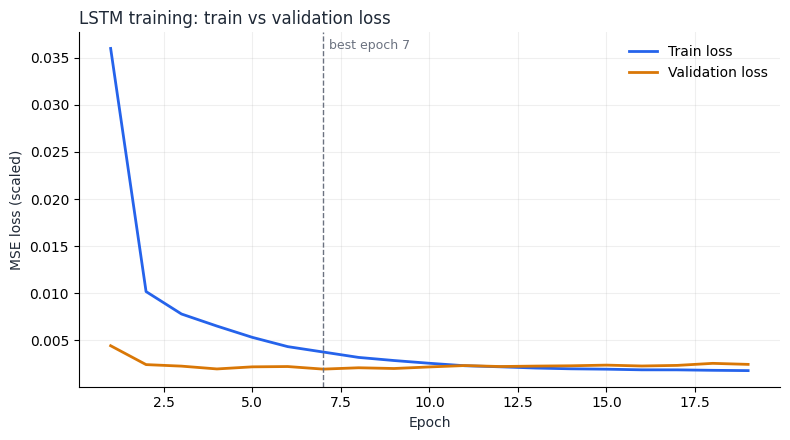

At best epoch: train 0.00378 | val 0.00196 | gap -0.00181
Reading it: validation loss rising while train loss keeps falling = overfitting. Early stopping already restored the best-epoch weights.


In [7]:
INK, MUTED = "#1f2937", "#6b7280"
C_TRAIN, C_VAL = "#2563eb", "#d97706"

fig, ax = plt.subplots(figsize=(8, 4.5))
ep = np.arange(1, len(history["train"]) + 1)
ax.plot(ep, history["train"], color=C_TRAIN, lw=2, label="Train loss")
ax.plot(ep, history["val"], color=C_VAL, lw=2, label="Validation loss")
ax.axvline(best_epoch, color=MUTED, lw=1, ls="--")
ax.annotate(f"best epoch {best_epoch}", (best_epoch, ax.get_ylim()[1]), xytext=(4, -12),
            textcoords="offset points", color=MUTED, fontsize=9)
ax.set_xlabel("Epoch", color=INK); ax.set_ylabel("MSE loss (scaled)", color=INK)
ax.set_title("LSTM training: train vs validation loss", color=INK, loc="left")
ax.grid(alpha=0.2); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(LOSS_FIG, dpi=150); plt.show()

gap = history["val"][best_epoch - 1] - history["train"][best_epoch - 1]
print(f"At best epoch: train {history['train'][best_epoch-1]:.5f} | val {history['val'][best_epoch-1]:.5f} | gap {gap:+.5f}")
print("Reading it: validation loss rising while train loss keeps falling = overfitting. "
      "Early stopping already restored the best-epoch weights.")

## 8. Predict the test set and evaluate

Predictions are inverse-transformed to SPEI units. Two reference points are reported alongside the LSTM:

- **Persistence baseline:** forecast = the current `spei_3m` (month *t*). The LSTM must beat this to add value.
- **Drought detection:** SPEI below the threshold counts as drought; precision, recall, and F1 show how well droughts are caught.

In [8]:
@torch.no_grad()
def predict(X):
    model.eval()
    outs = [model(torch.from_numpy(X[i:i + 2048]).to(DEVICE)).cpu().numpy()
            for i in range(0, len(X), 2048)]
    return np.concatenate(outs)

def reg_metrics(y_true, y_pred):
    err = y_pred - y_true
    ss_res, ss_tot = np.sum(err ** 2), np.sum((y_true - y_true.mean()) ** 2)
    return {"rmse": float(np.sqrt(np.mean(err ** 2))), "mae": float(np.mean(np.abs(err))),
            "r2": float(1 - ss_res / ss_tot) if ss_tot > 0 else None}

def drought_metrics(y_true, y_pred, thr=DROUGHT_THRESHOLD):
    t, p = y_true < thr, y_pred < thr
    tp, fp, fn = int((t & p).sum()), int((~t & p).sum()), int((t & ~p).sum())
    prec = tp / (tp + fp) if tp + fp else None
    rec = tp / (tp + fn) if tp + fn else None
    f1 = 2 * prec * rec / (prec + rec) if prec and rec else None
    return {"threshold": thr, "n_drought_months": int(t.sum()), "precision": prec, "recall": rec, "f1": f1}

def evaluate(X, y_scaled):
    y_true = inverse_target(y_scaled)
    y_pred = inverse_target(predict(X))
    y_persist = inverse_target(X[:, -1, TARGET_IDX])      # spei_3m at month t
    m = {"n_samples": int(len(y_true)), "lstm": reg_metrics(y_true, y_pred),
         "persistence": reg_metrics(y_true, y_persist),
         "lstm_drought": drought_metrics(y_true, y_pred),
         "persistence_drought": drought_metrics(y_true, y_persist)}
    m["skill_vs_persistence_rmse"] = 1 - m["lstm"]["rmse"] / m["persistence"]["rmse"]
    return m, y_true, y_pred, y_persist

val_metrics, *_ = evaluate(X_val, y_val)
test_metrics, y_true_test, y_pred_test, y_persist_test = evaluate(X_test, y_test)

print("TEST   LSTM       :", {k: round(v, 4) for k, v in test_metrics["lstm"].items() if v is not None})
print("TEST   persistence:", {k: round(v, 4) for k, v in test_metrics["persistence"].items() if v is not None})
print(f"Skill vs persistence (1 - RMSE ratio): {test_metrics['skill_vs_persistence_rmse']:+.3f}")
print("Drought detection (LSTM):", test_metrics["lstm_drought"])

TEST   LSTM       : {'rmse': 0.2449, 'mae': 0.1875, 'r2': 0.927}
TEST   persistence: {'rmse': 0.5658, 'mae': 0.4566, 'r2': 0.6102}
Skill vs persistence (1 - RMSE ratio): +0.567
Drought detection (LSTM): {'threshold': -1.0, 'n_drought_months': 2784, 'precision': 0.7937464142283419, 'recall': 0.9938936781609196, 'f1': 0.882615629984051}


## 9. Actual vs predicted

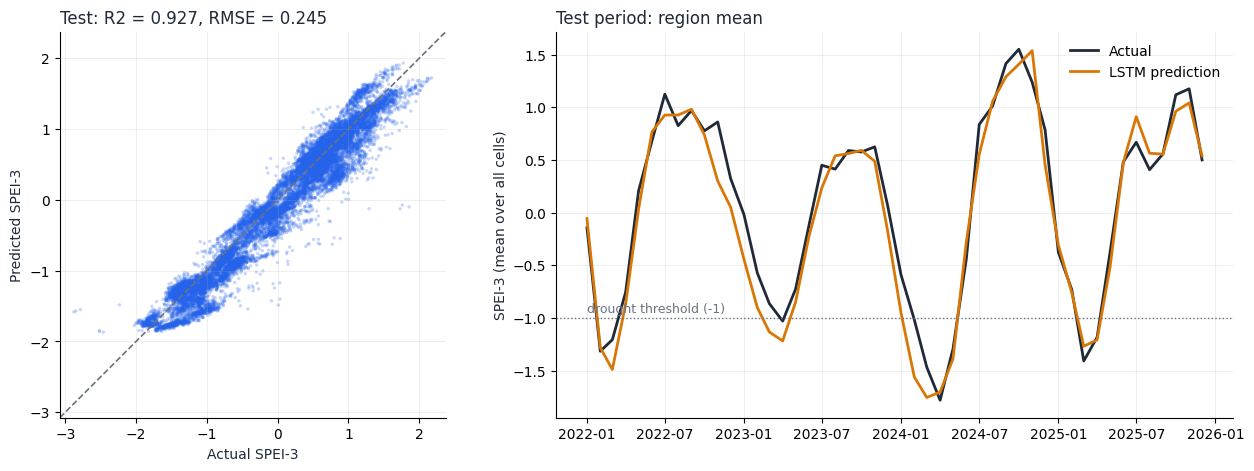

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})

# (a) scatter with 1:1 line
lim = [min(y_true_test.min(), y_pred_test.min()) - 0.2, max(y_true_test.max(), y_pred_test.max()) + 0.2]
ax1.scatter(y_true_test, y_pred_test, s=6, alpha=0.25, color=C_TRAIN, edgecolors="none")
ax1.plot(lim, lim, color=MUTED, lw=1.2, ls="--")
ax1.set_xlim(lim); ax1.set_ylim(lim); ax1.set_aspect("equal")
ax1.set_xlabel("Actual SPEI-3", color=INK); ax1.set_ylabel("Predicted SPEI-3", color=INK)
ax1.set_title(f"Test: R2 = {test_metrics['lstm']['r2']:.3f}, RMSE = {test_metrics['lstm']['rmse']:.3f}",
              color=INK, loc="left")

# (b) region-mean time series
ts = pd.DataFrame({"valid_time": meta_test["valid_time"], "actual": y_true_test, "pred": y_pred_test})
ts = ts.groupby("valid_time").mean()
ax2.plot(ts.index, ts["actual"], color=INK, lw=2, label="Actual")
ax2.plot(ts.index, ts["pred"], color=C_VAL, lw=2, label="LSTM prediction")
ax2.axhline(DROUGHT_THRESHOLD, color=MUTED, lw=1, ls=":")
ax2.annotate("drought threshold (-1)", (ts.index[0], DROUGHT_THRESHOLD), xytext=(0, 4),
             textcoords="offset points", color=MUTED, fontsize=9)
ax2.set_ylabel("SPEI-3 (mean over all cells)", color=INK)
ax2.set_title("Test period: region mean", color=INK, loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.grid(alpha=0.2); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(PRED_FIG, dpi=150); plt.show()

## 10. Save model, scaler, predictions, metrics

In [10]:
# Model + config (scaler is a separate file: models/lstm_scaler.pkl)
torch.save({
    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "model_class": "LSTMForecaster",
    "n_features": len(FEATURES), "hidden": HIDDEN, "layers": LAYERS, "dropout": DROPOUT,
    "features": FEATURES, "target": TARGET, "target_idx": TARGET_IDX,
    "window": T, "horizon": HORIZON, "best_epoch": best_epoch,
}, MODEL_PATH)

# Predictions (SPEI units)
pred_df = meta_test.copy()
pred_df["actual_spei_3m"] = y_true_test
pred_df["predicted_spei_3m"] = y_pred_test
pred_df["persistence_spei_3m"] = y_persist_test
pred_df["error"] = pred_df["predicted_spei_3m"] - pred_df["actual_spei_3m"]
pred_df = pred_df.sort_values(["valid_time", "latitude", "longitude"])
pred_df.to_csv(PRED_PATH, index=False)

# Metrics
metrics = {
    "model": "LSTM", "target": TARGET, "window_months": T, "horizon_months": HORIZON,
    "features": FEATURES,
    "split": {"train_targets_before": VAL_START, "validation": [VAL_START, TEST_START],
              "test_from": TEST_START,
              "test_last_target_month": f"{tgt_time[test_m].max():%Y-%m}",
              "n_train": int(train_m.sum()), "n_val": int(val_m.sum()), "n_test": int(test_m.sum())},
    "training": {"best_epoch": best_epoch, "epochs_run": len(history["train"]),
                 "best_val_loss_scaled": best_val,
                 "final_train_loss_scaled": history["train"][-1], "seed": SEED},
    "validation": val_metrics,
    "test": test_metrics,
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2))

for p in (MODEL_PATH, SCALER_PATH, PRED_PATH, METRICS_PATH, LOSS_FIG, PRED_FIG):
    print(f"{p.stat().st_size:>10,} B  {p.relative_to(ROOT)}")

   229,639 B  models/lstm_spei3m.pt
     1,279 B  models/lstm_scaler.pkl
 2,145,428 B  data/gold/drought_forecasting/lstm_predictions_2022_2025.csv
     2,336 B  reports/evaluation/lstm_metrics.json
    62,520 B  reports/figures/lstm_loss_curve.png
   229,159 B  reports/figures/lstm_actual_vs_pred.png


## 11. Reload check and how to reuse the saved files

In [11]:
ckpt = torch.load(MODEL_PATH, map_location="cpu")
reloaded = LSTMForecaster(ckpt["n_features"], ckpt["hidden"], ckpt["layers"], ckpt["dropout"])
reloaded.load_state_dict(ckpt["state_dict"]); reloaded.eval()
scaler_loaded = joblib.load(SCALER_PATH)

with torch.no_grad():
    chk = reloaded(torch.from_numpy(X_test[:256])).numpy()
assert np.allclose(chk, predict(X_test[:256]), atol=1e-5), "Reloaded model differs from trained model"

# Full inverse transform of a scaled feature matrix, e.g. the target column:
#   scaler_loaded.inverse_transform(scaled_matrix)[:, ckpt["target_idx"]]
print("Reload OK - predictions match. Target column index:", ckpt["target_idx"])

Reload OK - predictions match. Target column index: 6
